In [ ]:
#pip install keras_tuner

In [ ]:
#pip install "numpy<2"

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import keras_tuner as kt
#df = pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")


2026-05-04 00:25:02.364456: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-04 00:25:03.215299: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-05-04 00:25:03.418288: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-05-04 00:25:03.418330: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-05-04 00:25:03.418422: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

In [2]:
df

,timestamp,symbol,open,high,low,close,volume,sma_10,sma_50,ema_20,...,sum_of_scores,avg_of_scores,normalized_avg,max_of_scores,min_of_scores,normalized_min,normalized_max,avg_score_of_normalized_min,avg_score_of_normalized_max,avg_score_of_normalized_avg
0,2023-01-03 09:00:00,TSLA,120.02,121.23,115.94,118.52,1306706,118.5200,118.5200,118.520000,...,"[-7, 2, 7, 1, -2, 5, 2, 0, 1, 5]","[-3.5, 1.0, 3.5, 0.5, -1.0, 2.5, 1.0, 0.0, 0.5...","[-0.7, 0.2, 0.7, 0.1, -0.2, 0.5, 0.2, 0.0, 0.1...","[-3, 1, 5, 4, 0, 5, 3, 1, 1, 3]","[-4, 1, 2, -3, -2, 0, -1, -1, 0, 2]","[-0.8, 0.2, 0.4, -0.6, -0.4, 0.0, -0.2, -0.2, ...","[-0.6, 0.2, 1.0, 0.8, 0.0, 1.0, 0.6, 0.2, 0.2,...",-0.12,0.40,0.140000
1,2023-01-03 10:00:00,TSLA,118.53,120.50,118.20,120.38,568635,119.4500,119.4500,118.697143,...,"[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[2.0, 5.0, 0.0, 3.0, -1.0, 4.0, 0.0, -2.0, -2....","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....","[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....",0.26,0.26,0.260000
2,2023-01-03 11:00:00,TSLA,120.28,120.50,117.95,118.61,547403,119.1700,119.1700,118.688844,...,"[-18, 14, 10, 10, 2, 11, -2, 15, -7, -7]","[-3.0, 2.3333333333333335, 1.6666666666666667,...","[-0.6, 0.4666666666666667, 0.33333333333333337...","[-2, 5, 4, 5, 1, 5, 3, 6, 1, 2]","[-5, 0, 0, -2, -1, -1, -4, 0, -5, -5]","[-1.0, 0.0, 0.0, -0.4, -0.2, -0.2, -0.8, 0.0, ...","[-0.4, 1.0, 0.8, 1.0, 0.2, 1.0, 0.6, 1.2, 0.2,...",-0.46,0.60,0.093333
3,2023-01-03 12:00:00,TSLA,118.63,118.99,116.61,118.28,1529445,118.9475,118.9475,118.649906,...,"[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-4.0, 0.0, 3.0, -1.0, -5.0, 0.0, 0.0, -2.0, -...","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...","[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...",-0.24,-0.24,-0.240000
4,2023-01-03 13:00:00,TSLA,118.32,121.90,116.61,118.93,2886437,118.9440,118.9440,118.676582,...,"[-20, 2, 19, 16, 6, 16, 4, 5, -2, 9]","[-2.5, 0.25, 2.375, 2.0, 0.75, 2.0, 0.5, 0.625...","[-0.5, 0.05, 0.475, 0.4, 0.15, 0.4, 0.1, 0.125...","[0, 2, 5, 4, 5, 5, 3, 3, 2, 5]","[-5, -4, 0, -4, -5, -2, -2, -3, -5, -1]","[-1.0, -0.8, 0.0, -0.8, -1.0, -0.4, -0.4, -0.6...","[0.0, 0.4, 1.0, 0.8, 1.0, 1.0, 0.6, 0.6, 0.4, ...",-0.62,0.68,0.137500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1032,2023-12-08 13:00:00,TSLA,242.19,243.37,239.75,240.40,1406899,242.3970,241.1094,241.760952,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1033,2023-12-08 14:00:00,TSLA,240.46,243.65,239.27,242.40,15237079,242.3730,241.2916,241.821814,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1034,2023-12-08 15:00:00,TSLA,242.40,245.23,242.40,245.19,22432349,242.6320,241.5218,242.142593,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1035,2023-12-08 16:00:00,TSLA,245.19,245.27,241.67,241.97,15853691,242.5470,241.5982,242.126156,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0,

In [1]:
"""
================================================================================
Tesla Stock Forecasting Pipeline
================================================================================
Models:
  1. Naive Baseline (random walk)
  2. Improved LSTM (two versions: prices vs returns) with hyperparameter tuning
  3. Temporal Fusion Transformer (TFT) - simplified Keras implementation
  4. N-BEATS

Best practices applied:
  - Split BEFORE normalizing (no data leakage)
  - TimeSeriesSplit for walk-forward CV
  - EarlyStopping + ReduceLROnPlateau
  - BayesianOptimization for hyperparameter tuning
  - Multiple regression metrics (RMSE, MAE, MAPE, R2, Directional Accuracy)
  - Mean +/- std reported across folds
  - Sanity check vs naive baseline
================================================================================
"""

# ============================================================================
# SETUP
# ============================================================================
# If running in Jupyter, run these in a cell first (NOT in a .py script):
#   !pip install keras_tuner
#   !pip install "numpy<2"   # only if you hit ABI errors

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input, Dense, LSTM, Dropout, Layer, BatchNormalization,
    LayerNormalization, MultiHeadAttention, GlobalAveragePooling1D,
    Concatenate, Add, Lambda
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import backend as K
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, r2_score
)
import keras_tuner as kt

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ============================================================================
# 1. CONFIG
# ============================================================================
CSV_PATH    = "brian_news_stocks_tesla_2023_processses_with_agg.csv"
TARGET_COL  = "close"
TIME_COL    = "timestamp"
LOOKBACK    = 30
N_SPLITS    = 5          # walk-forward folds
MAX_TRIALS  = 15         # Bayesian tuner trials (was 5 - too few)
TUNE_EPOCHS = 30
FIT_EPOCHS  = 150        # 1000 was overkill
BATCH_SIZE  = 64

# ============================================================================
# 2. UTILITIES
# ============================================================================
def create_windows(series, look_back=LOOKBACK):
    """Convert a 1D series into (X, y) supervised-learning windows."""
    X, y = [], []
    for i in range(len(series) - look_back):
        X.append(series[i : i + look_back])
        y.append(series[i + look_back])
    return np.array(X), np.array(y)


def regression_metrics(y_true, y_pred, prev_values=None):
    """
    Compute regression metrics. `prev_values` is the value at t-1 used for
    directional accuracy when predicting raw prices (so we know the sign of
    the *change*).
    """
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()

    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae  = float(mean_absolute_error(y_true, y_pred))
    # Avoid divide-by-zero in MAPE
    nonzero = y_true != 0
    mape = float(mean_absolute_percentage_error(
        y_true[nonzero], y_pred[nonzero])) * 100 if nonzero.any() else np.nan
    r2   = float(r2_score(y_true, y_pred))

    # Directional accuracy
    if prev_values is not None:
        prev_values = np.asarray(prev_values).flatten()
        true_dir = np.sign(y_true - prev_values)
        pred_dir = np.sign(y_pred - prev_values)
    else:
        # If we're already in returns/diff space, sign tells direction directly
        true_dir = np.sign(y_true)
        pred_dir = np.sign(y_pred)
    da = float(np.mean(true_dir == pred_dir) * 100)

    return {"RMSE": rmse, "MAE": mae, "MAPE%": mape, "R2": r2, "DA%": da}


def summarize(metrics_list, name=""):
    """Mean +/- std across folds."""
    keys = metrics_list[0].keys()
    print(f"\n=== {name} (mean +/- std across {len(metrics_list)} folds) ===")
    summary = {}
    for k in keys:
        vals = [m[k] for m in metrics_list]
        summary[k] = (np.mean(vals), np.std(vals))
        print(f"  {k:8s}: {np.mean(vals):8.4f} +/- {np.std(vals):.4f}")
    return summary



2026-05-04 00:50:34.630311: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-04 00:50:34.642122: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-05-04 00:50:34.681476: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-05-04 00:50:34.681505: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-05-04 00:50:34.681534: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

In [2]:

# ============================================================================
# 3. LOAD DATA
# ============================================================================

df = pd.read_csv(CSV_PATH).sort_values(by=TIME_COL).reset_index(drop=True)
prices = df[TARGET_COL].values.astype("float32")
returns = np.diff(prices, prepend=prices[0])  # daily price change

print(f"Data: {len(prices)} rows, price range [{prices.min():.2f}, {prices.max():.2f}]")


Data: 1037 rows, price range [103.10, 283.70]


In [3]:

# ============================================================================
# 4. NAIVE BASELINE (random walk: y_hat_t = y_{t-1})
# ============================================================================
# This is the bar every fancy model must beat. If your LSTM/TFT/N-BEATS doesn't
# beat this, the model isn't learning anything useful.
def evaluate_naive(prices, n_splits=N_SPLITS, look_back=LOOKBACK):
    X, y = create_windows(prices, look_back)
    tscv = TimeSeriesSplit(n_splits=n_splits)
    fold_metrics = []
    for fold, (_, test_idx) in enumerate(tscv.split(X), 1):
        X_te, y_te = X[test_idx], y[test_idx]
        # Predict that tomorrow == today (last value in the window)
        preds = X_te[:, -1]
        prev  = X_te[:, -1]   # same here (used for DA)
        m = regression_metrics(y_te, preds, prev_values=prev)
        fold_metrics.append(m)
        print(f"  Naive fold {fold}: RMSE={m['RMSE']:.2f} DA={m['DA%']:.2f}%")
    return fold_metrics


In [4]:



# ============================================================================
# 5. IMPROVED LSTM (two versions: prices and returns)
# ============================================================================
def build_lstm(hp, look_back=LOOKBACK, n_features=1):
    """LSTM hypermodel. Tunes layers, units, dropout, lr, and batch size."""
    model = Sequential()
    n_layers = hp.Int("num_layers", 1, 3)
    for i in range(n_layers):
        units = hp.Int(f"units_{i}", 32, 128, step=32)
        dropout = hp.Float(f"dropout_{i}", 0.0, 0.4, step=0.1)
        return_sequences = (i < n_layers - 1)
        if i == 0:
            model.add(LSTM(units, return_sequences=return_sequences,
                           input_shape=(look_back, n_features)))
        else:
            model.add(LSTM(units, return_sequences=return_sequences))
        model.add(Dropout(dropout))
    model.add(Dense(1, activation="linear"))
    lr = hp.Choice("lr", [1e-2, 1e-3, 1e-4])
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="huber")
    return model


def tune_lstm(X_train, y_train, project_name):
    """Bayesian search on a single train/val slice (fast, then we walk-forward)."""
    val_split = int(len(X_train) * 0.8)
    X_tr, X_va = X_train[:val_split], X_train[val_split:]
    y_tr, y_va = y_train[:val_split], y_train[val_split:]

    tuner = kt.BayesianOptimization(
        build_lstm,
        objective="val_loss",
        max_trials=MAX_TRIALS,
        directory="kt_dir",
        project_name=project_name,
        overwrite=True,
        seed=SEED,
    )
    es = EarlyStopping(monitor="val_loss", patience=8,
                       min_delta=1e-4, restore_best_weights=True)
    tuner.search(X_tr, y_tr, epochs=TUNE_EPOCHS,
                 validation_data=(X_va, y_va),
                 callbacks=[es], verbose=0)
    return tuner.get_best_hyperparameters(1)[0]


def run_lstm(series, mode, project_name):
    """
    mode = 'price'   -> predict raw price (use MinMaxScaler)
    mode = 'returns' -> predict daily diff (use StandardScaler, more stationary)
    """
    print(f"\n>>> LSTM mode={mode}")
    X_all, y_all = create_windows(series, LOOKBACK)
    X_all = X_all.reshape(-1, LOOKBACK, 1)

    # Quick tune on the first 70% to get hyperparameters
    split = int(len(X_all) * 0.7)
    best_hp = tune_lstm(X_all[:split], y_all[:split], project_name)
    print(f"  Best HPs: {best_hp.values}")

    # Walk-forward CV with the best hyperparameters
    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    fold_metrics = []
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X_all), 1):
        X_tr_raw, X_te_raw = X_all[tr_idx], X_all[te_idx]
        y_tr_raw, y_te_raw = y_all[tr_idx], y_all[te_idx]

        # Fit scaler on TRAIN only (no leakage)
        Scaler = StandardScaler if mode == "returns" else MinMaxScaler
        sx = Scaler().fit(X_tr_raw.reshape(-1, 1))
        sy = Scaler().fit(y_tr_raw.reshape(-1, 1))
        X_tr = sx.transform(X_tr_raw.reshape(-1, 1)).reshape(X_tr_raw.shape)
        X_te = sx.transform(X_te_raw.reshape(-1, 1)).reshape(X_te_raw.shape)
        y_tr = sy.transform(y_tr_raw.reshape(-1, 1)).flatten()
        y_te = sy.transform(y_te_raw.reshape(-1, 1)).flatten()

        model = build_lstm(best_hp)
        callbacks = [
            EarlyStopping(monitor="val_loss", patience=20,
                          min_delta=1e-4, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", patience=8, factor=0.5),
        ]
        model.fit(X_tr, y_tr, epochs=FIT_EPOCHS, batch_size=BATCH_SIZE,
                  validation_data=(X_te, y_te), callbacks=callbacks, verbose=0)

        preds = sy.inverse_transform(model.predict(X_te, verbose=0)).flatten()
        # Last value of each input window (in original scale) -> previous value
        prev = X_te_raw[:, -1, 0]
        m = regression_metrics(y_te_raw, preds,
                               prev_values=prev if mode == "price" else None)
        fold_metrics.append(m)
        print(f"  LSTM-{mode} fold {fold}: RMSE={m['RMSE']:.4f} DA={m['DA%']:.2f}%")
    return fold_metrics


In [5]:


# ============================================================================
# 6. TEMPORAL FUSION TRANSFORMER (simplified Keras implementation)
# ============================================================================
# Full TFT (Lim et al. 2021) has variable-selection, gating, and quantile
# outputs across static/known/observed inputs. For a single-series univariate
# task, a faithful but compact implementation keeps:
#   - LSTM encoder
#   - Multi-head self-attention block
#   - Gated residual + LayerNorm
#   - Pointwise feed-forward
# This captures TFT's core "LSTM + interpretable attention" idea.
def gated_residual_network(x, units, dropout=0.1):
    """Gated Residual Network: GLU-style gate + skip connection + LayerNorm."""
    h = Dense(units, activation="elu")(x)
    h = Dense(units)(h)
    h = Dropout(dropout)(h)
    gate = Dense(units, activation="sigmoid")(x)
    if x.shape[-1] != units:
        x = Dense(units)(x)
    return LayerNormalization()(Add()([x, h * gate]))


def build_tft(hp, look_back=LOOKBACK, n_features=1):
    units    = hp.Int("units", 32, 128, step=32)
    n_heads  = hp.Choice("n_heads", [2, 4])
    dropout  = hp.Float("dropout", 0.0, 0.3, step=0.1)
    lr       = hp.Choice("lr", [1e-3, 5e-4, 1e-4])

    inp = Input(shape=(look_back, n_features))
    # 1) Local processing (LSTM encoder, like TFT)
    enc = LSTM(units, return_sequences=True)(inp)
    enc = gated_residual_network(enc, units, dropout)
    # 2) Self-attention over time (the interpretability part)
    attn = MultiHeadAttention(num_heads=n_heads, key_dim=units)(enc, enc)
    attn = Dropout(dropout)(attn)
    x = LayerNormalization()(Add()([enc, attn]))
    x = gated_residual_network(x, units, dropout)
    # 3) Pool + output
    x = GlobalAveragePooling1D()(x)
    out = Dense(1, activation="linear")(x)

    model = Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="huber")
    return model


def run_tft(series, mode, project_name):
    print(f"\n>>> TFT mode={mode}")
    X_all, y_all = create_windows(series, LOOKBACK)
    X_all = X_all.reshape(-1, LOOKBACK, 1)

    # Tune on first 70%
    split = int(len(X_all) * 0.7)
    val_split = int(split * 0.8)
    tuner = kt.BayesianOptimization(
        build_tft, objective="val_loss",
        max_trials=MAX_TRIALS, directory="kt_dir",
        project_name=project_name, overwrite=True, seed=SEED,
    )
    es = EarlyStopping(monitor="val_loss", patience=8,
                       min_delta=1e-4, restore_best_weights=True)
    tuner.search(X_all[:val_split], y_all[:val_split],
                 validation_data=(X_all[val_split:split], y_all[val_split:split]),
                 epochs=TUNE_EPOCHS, callbacks=[es], verbose=0)
    best_hp = tuner.get_best_hyperparameters(1)[0]
    print(f"  Best HPs: {best_hp.values}")

    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    fold_metrics = []
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X_all), 1):
        X_tr_raw, X_te_raw = X_all[tr_idx], X_all[te_idx]
        y_tr_raw, y_te_raw = y_all[tr_idx], y_all[te_idx]
        Scaler = StandardScaler if mode == "returns" else MinMaxScaler
        sx = Scaler().fit(X_tr_raw.reshape(-1, 1))
        sy = Scaler().fit(y_tr_raw.reshape(-1, 1))
        X_tr = sx.transform(X_tr_raw.reshape(-1, 1)).reshape(X_tr_raw.shape)
        X_te = sx.transform(X_te_raw.reshape(-1, 1)).reshape(X_te_raw.shape)
        y_tr = sy.transform(y_tr_raw.reshape(-1, 1)).flatten()
        y_te = sy.transform(y_te_raw.reshape(-1, 1)).flatten()

        model = build_tft(best_hp)
        callbacks = [
            EarlyStopping(monitor="val_loss", patience=20,
                          min_delta=1e-4, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", patience=8, factor=0.5),
        ]
        model.fit(X_tr, y_tr, epochs=FIT_EPOCHS, batch_size=BATCH_SIZE,
                  validation_data=(X_te, y_te), callbacks=callbacks, verbose=0)

        preds = sy.inverse_transform(model.predict(X_te, verbose=0)).flatten()
        prev = X_te_raw[:, -1, 0]
        m = regression_metrics(y_te_raw, preds,
                               prev_values=prev if mode == "price" else None)
        fold_metrics.append(m)
        print(f"  TFT-{mode} fold {fold}: RMSE={m['RMSE']:.4f} DA={m['DA%']:.2f}%")
    return fold_metrics


In [6]:

# ============================================================================
# 7. N-BEATS (Oreshkin et al. 2020)
# ============================================================================
# N-BEATS works on flat 1D windows (not sequences). Each "block" predicts a
# backcast (reconstruction of the input) and a forecast. Residuals from the
# backcast feed the next block. We implement the generic version.
def nbeats_block(x, units, theta_size, horizon, look_back):
    """One generic N-BEATS block."""
    h = x
    for _ in range(4):
        h = Dense(units, activation="relu")(h)
    theta_b = Dense(look_back, activation="linear")(h)   # backcast
    theta_f = Dense(horizon,   activation="linear")(h)   # forecast
    return theta_b, theta_f


def build_nbeats(hp, look_back=LOOKBACK, horizon=1):
    units      = hp.Int("units", 64, 256, step=64)
    n_blocks   = hp.Int("n_blocks", 2, 4)
    theta_size = hp.Int("theta_size", 8, 32, step=8)
    lr         = hp.Choice("lr", [1e-3, 5e-4, 1e-4])

    inp = Input(shape=(look_back,))
    residual = inp
    forecast = Lambda(lambda z: tf.zeros_like(z[:, :horizon]))(inp)

    for _ in range(n_blocks):
        backcast, block_fc = nbeats_block(residual, units, theta_size,
                                          horizon, look_back)
        residual = tf.keras.layers.Subtract()([residual, backcast])
        forecast = Add()([forecast, block_fc])

    model = Model(inp, forecast)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="huber")
    return model


def run_nbeats(series, mode, project_name):
    print(f"\n>>> N-BEATS mode={mode}")
    X_all, y_all = create_windows(series, LOOKBACK)  # X is 2D (samples, look_back)

    split = int(len(X_all) * 0.7)
    val_split = int(split * 0.8)
    tuner = kt.BayesianOptimization(
        build_nbeats, objective="val_loss",
        max_trials=MAX_TRIALS, directory="kt_dir",
        project_name=project_name, overwrite=True, seed=SEED,
    )
    es = EarlyStopping(monitor="val_loss", patience=8,
                       min_delta=1e-4, restore_best_weights=True)
    tuner.search(X_all[:val_split], y_all[:val_split],
                 validation_data=(X_all[val_split:split], y_all[val_split:split]),
                 epochs=TUNE_EPOCHS, callbacks=[es], verbose=0)
    best_hp = tuner.get_best_hyperparameters(1)[0]
    print(f"  Best HPs: {best_hp.values}")

    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    fold_metrics = []
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X_all), 1):
        X_tr_raw, X_te_raw = X_all[tr_idx], X_all[te_idx]
        y_tr_raw, y_te_raw = y_all[tr_idx], y_all[te_idx]
        Scaler = StandardScaler if mode == "returns" else MinMaxScaler
        sx = Scaler().fit(X_tr_raw.reshape(-1, 1))
        sy = Scaler().fit(y_tr_raw.reshape(-1, 1))
        X_tr = sx.transform(X_tr_raw.reshape(-1, 1)).reshape(X_tr_raw.shape)
        X_te = sx.transform(X_te_raw.reshape(-1, 1)).reshape(X_te_raw.shape)
        y_tr = sy.transform(y_tr_raw.reshape(-1, 1)).flatten()
        y_te = sy.transform(y_te_raw.reshape(-1, 1)).flatten()

        model = build_nbeats(best_hp)
        callbacks = [
            EarlyStopping(monitor="val_loss", patience=20,
                          min_delta=1e-4, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", patience=8, factor=0.5),
        ]
        model.fit(X_tr, y_tr, epochs=FIT_EPOCHS, batch_size=BATCH_SIZE,
                  validation_data=(X_te, y_te), callbacks=callbacks, verbose=0)

        preds = sy.inverse_transform(model.predict(X_te, verbose=0)).flatten()
        prev = X_te_raw[:, -1]
        m = regression_metrics(y_te_raw, preds,
                               prev_values=prev if mode == "price" else None)
        fold_metrics.append(m)
        print(f"  NBEATS-{mode} fold {fold}: RMSE={m['RMSE']:.4f} DA={m['DA%']:.2f}%")
    return fold_metrics



NAIVE BASELINE (predict y_t = y_{t-1})
  Naive fold 1: RMSE=2.65 DA=1.20%
  Naive fold 2: RMSE=4.95 DA=0.60%
  Naive fold 3: RMSE=1.81 DA=0.60%
  Naive fold 4: RMSE=4.74 DA=0.00%
  Naive fold 5: RMSE=2.15 DA=0.00%

=== Naive (mean +/- std across 5 folds) ===
  RMSE    :   3.2589 +/- 1.3227
  MAE     :   1.3464 +/- 0.2258
  MAPE%   :   0.5967 +/- 0.0994
  R2      :   0.9479 +/- 0.0431
  DA%     :   0.4790 +/- 0.4481

LSTM - PRICE prediction

>>> LSTM mode=price


2026-05-04 00:52:36.721637: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


  Best HPs: {'num_layers': 3, 'units_0': 128, 'dropout_0': 0.2, 'lr': 0.01, 'units_1': 128, 'dropout_1': 0.2, 'units_2': 96, 'dropout_2': 0.1}
  LSTM-price fold 1: RMSE=8.4384 DA=55.09%
  LSTM-price fold 2: RMSE=39.5141 DA=52.10%
  LSTM-price fold 3: RMSE=3.4134 DA=46.71%
  LSTM-price fold 4: RMSE=8.3906 DA=55.09%
  LSTM-price fold 5: RMSE=3.7911 DA=53.29%

=== LSTM-price (mean +/- std across 5 folds) ===
  RMSE    :  12.7095 +/- 13.5745
  MAE     :   9.4049 +/- 11.0136
  MAPE%   :   4.6609 +/- 5.6585
  R2      :   0.5660 +/- 0.3579
  DA%     :  52.4551 +/- 3.0907

LSTM - RETURNS prediction (stationary)

>>> LSTM mode=returns
  Best HPs: {'num_layers': 2, 'units_0': 128, 'dropout_0': 0.4, 'lr': 0.01, 'units_1': 64, 'dropout_1': 0.2, 'units_2': 32, 'dropout_2': 0.2}
  LSTM-returns fold 1: RMSE=2.6451 DA=53.89%
  LSTM-returns fold 2: RMSE=4.9426 DA=55.09%
  LSTM-returns fold 3: RMSE=1.8082 DA=50.30%
  LSTM-returns fold 4: RMSE=4.7385 DA=53.89%
  LSTM-returns fold 5: RMSE=2.1317 DA=55.09%

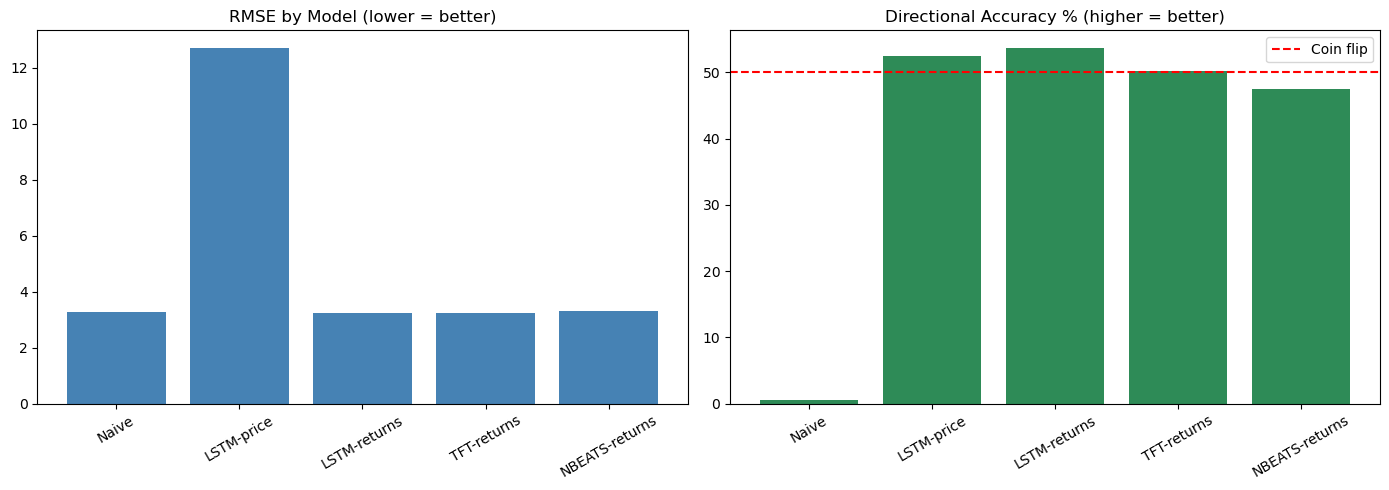

Saved -> model_comparison.png


In [7]:



# ============================================================================
# 8. RUN EVERYTHING
# ============================================================================
if __name__ == "__main__":
    results = {}

    print("\n" + "="*70)
    print("NAIVE BASELINE (predict y_t = y_{t-1})")
    print("="*70)
    results["Naive"] = evaluate_naive(prices)
    summarize(results["Naive"], "Naive")

    print("\n" + "="*70)
    print("LSTM - PRICE prediction")
    print("="*70)
    results["LSTM-price"] = run_lstm(prices, "price", "lstm_price")
    summarize(results["LSTM-price"], "LSTM-price")

    print("\n" + "="*70)
    print("LSTM - RETURNS prediction (stationary)")
    print("="*70)
    results["LSTM-returns"] = run_lstm(returns, "returns", "lstm_returns")
    summarize(results["LSTM-returns"], "LSTM-returns")

    print("\n" + "="*70)
    print("TFT - RETURNS prediction")
    print("="*70)
    results["TFT-returns"] = run_tft(returns, "returns", "tft_returns")
    summarize(results["TFT-returns"], "TFT-returns")

    print("\n" + "="*70)
    print("N-BEATS - RETURNS prediction")
    print("="*70)
    results["NBEATS-returns"] = run_nbeats(returns, "returns", "nbeats_returns")
    summarize(results["NBEATS-returns"], "NBEATS-returns")

    # ------------------------------------------------------------------
    # 9. FINAL COMPARISON TABLE
    # ------------------------------------------------------------------
    print("\n" + "="*70)
    print("FINAL COMPARISON (mean across folds)")
    print("="*70)
    rows = []
    for name, folds in results.items():
        avg = {k: np.mean([f[k] for f in folds]) for k in folds[0]}
        rows.append({"Model": name, **avg})
    df_out = pd.DataFrame(rows).round(4)
    print(df_out.to_string(index=False))
    df_out.to_csv("model_comparison.csv", index=False)
    print("\nSaved -> model_comparison.csv")

    # Bar chart of RMSE and DA
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].bar(df_out["Model"], df_out["RMSE"], color="steelblue")
    axes[0].set_title("RMSE by Model (lower = better)")
    axes[0].tick_params(axis="x", rotation=30)
    axes[1].bar(df_out["Model"], df_out["DA%"], color="seagreen")
    axes[1].set_title("Directional Accuracy % (higher = better)")
    axes[1].axhline(50, color="red", linestyle="--", label="Coin flip")
    axes[1].tick_params(axis="x", rotation=30)
    axes[1].legend()
    plt.tight_layout()
    plt.savefig("model_comparison.png", dpi=120)
    plt.show()
    print("Saved -> model_comparison.png")